 وارد کردن کتابخانه‌ها

In [1]:
import pandas as pd
import numpy as np
import re
import html
import math

from collections import Counter, defaultdict
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

 تنظیم مسیر فایل‌ها و پارامترهای مدل

In [2]:
TRAIN_PATH = "train_data.csv"
TEST_PATH = "test_data.csv"

CHUNK_SIZE = 20000
SAMPLE_SIZE = 30000

MAX_VOCAB = 20000
MAX_LEN = 400

STATES = 3
ALPHA = 0.1

CLASSES = [0, 1]

بارگذاری و پاک‌سازی داده‌های آموزش

In [3]:
np.random.seed(42)
train_parts = []

for chunk in pd.read_csv(TRAIN_PATH, chunksize=CHUNK_SIZE):
    # حذف داده‌های ناقص
    chunk = chunk.dropna(subset=['reviewText', 'overall']).copy()
    # تبدیل برچسب به عدد
    chunk['overall'] = pd.to_numeric(chunk['overall'], errors='coerce')
    chunk = chunk.dropna(subset=['overall'])
    # فقط امتیازهای 1 تا 5
    chunk = chunk[chunk['overall'].isin([1, 2, 3, 4, 5])]
    train_parts.append(chunk)

# ترکیب داده‌ها
train_df = pd.concat(train_parts, ignore_index=True)
#تبدیل امتیازها به دو کلاس 
train_df['overall'] = train_df['overall'].apply(lambda x: 0 if x <= 3 else 1)
train_df['overall'] = train_df['overall'].astype(int)

بررسی توزیع کلاس‌ها قبل از متوازن سازی

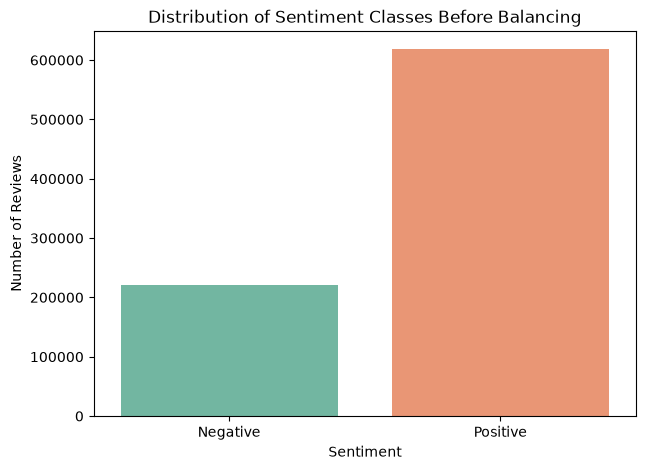

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x='overall',
    hue='overall',
    palette='Set2',
    legend=False)

plt.xticks([0, 1], ['Negative', 'Positive'])
plt.title('Distribution of Sentiment Classes Before Balancing')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

plt.show()

متوازن سازی تعداد نمونه‌های دو کلاس

In [5]:
n_per_class = min(
    SAMPLE_SIZE // 2,
    train_df['overall'].value_counts().min())

# نمونه‌گیری تصادفی از هر کلاس
class_0 = train_df[train_df['overall'] == 0].sample(n=n_per_class, random_state=42)
class_1 = train_df[train_df['overall'] == 1].sample(n=n_per_class, random_state=42)

# ترکیب دو کلاس متوازن
train_df = pd.concat([class_0, class_1], ignore_index=True)

# به‌هم زدن ترتیب داده‌ها
train_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Train shape:", train_df.shape)
print("\nتوزیع کلاس‌های جدید:")
print(train_df['overall'].value_counts().sort_index())

Train shape: (30000, 11)

توزیع کلاس‌های جدید:
overall
0    15000
1    15000
Name: count, dtype: int64


نمایش تعداد و درصد نمونه‌های هر کلاس

In [6]:
print("تعداد نمونه‌های هر کلاس:")
print(train_df['overall'].value_counts().sort_index())
print("\nدرصد هر کلاس:")
print(train_df['overall'].value_counts(normalize=True).sort_index() * 100)

تعداد نمونه‌های هر کلاس:
overall
0    15000
1    15000
Name: count, dtype: int64

درصد هر کلاس:
overall
0    50.0
1    50.0
Name: proportion, dtype: float64


تعریف تابع پیش‌پردازش متن

In [7]:
def preprocess_text(text):

    if pd.isna(text):
        return ""

    text = str(text)

    # تبدیل حروف به کوچک
    text = text.lower()

    # تبدیل کاراکترهای HTML
    text = html.unescape(text)

    # حذف تگ‌های HTML
    text = re.sub(r"<.*?>", " ", text)

    # حذف لینک‌ها
    text = re.sub(r"http\S+|www\S+", " ", text)

    # حذف کاراکترهای غیرضروری
    text = re.sub(r"[^a-z0-9'\s!?]", " ", text)

    # حذف فاصله‌های اضافی
    text = re.sub(r"\s+", " ", text).strip()

    return text

ترکیب عنوان و متن نظر

In [8]:
def combine_text(row):

    summary = (
        str(row["summary"])
        if pd.notna(row["summary"])
        else ""
    )

    review = (
        str(row["reviewText"])
        if pd.notna(row["reviewText"])
        else ""
    )

    combined = summary + " " + review

    return preprocess_text(combined)


train_df["text"] = train_df.apply(
    combine_text,
    axis=1
)

print(
    train_df[["overall", "text"]].head()
)

   overall                                               text
0        0  all capacitors checked out perfectly fine boot...
1        1  works well in all aspects this keyboard has la...
2        1  nice cover back cover is plastic and the front...
3        1  very satisfied replaced the 1tb in my asus lap...
4        0  dropped to 3 star 8 30 16 9 month follow up pu...


تقسیم داده‌های آموزش و اعتبارسنجی

In [9]:
X = train_df['text']

y = train_df['overall'].astype(int)

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", len(X_train))
print("X_val:", len(X_val))

print("\nتوزیع کلاس‌ها در Train:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nتوزیع کلاس‌ها در Validation:")
print(y_val.value_counts(normalize=True).sort_index())

X_train: 24000
X_val: 6000

توزیع کلاس‌ها در Train:
overall
0    0.5
1    0.5
Name: proportion, dtype: float64

توزیع کلاس‌ها در Validation:
overall
0    0.5
1    0.5
Name: proportion, dtype: float64


توکن‌سازی متن و ساخت بیگرام‌ها

In [10]:
def tokenize(text):

    words = text.split()

    words = words[:MAX_LEN]

    bigrams = []

    for i in range(len(words) - 1):

        bigrams.append(
            words[i] + "_" + words[i + 1]
        )

    return words + bigrams

ساخت واژگان از داده‌های آموزش

In [11]:
word_counts = Counter()

for text in X_train:
    word_counts.update(tokenize(text))

vocab = set(
    word for word, count in word_counts.most_common(MAX_VOCAB)
)

vocab.add("<UNK>")

print("Vocabulary size:", len(vocab))

Vocabulary size: 20001


تعریف تابع کدگذاری متن

In [12]:
def encode(text):

    words = tokenize(text)

    return [
        word if word in vocab else "<UNK>"
        for word in words
    ]

کدگذاری داده‌های آموزش و اعتبارسنجی

In [13]:
X_train_encoded = [
    encode(text)
    for text in X_train
]

X_val_encoded = [
    encode(text)
    for text in X_val
]

print("Train encoded:", len(X_train_encoded))
print("Validation encoded:", len(X_val_encoded))

Train encoded: 24000
Validation encoded: 6000


تعریف کلاس مدل HMM

In [14]:
class SimpleHMM:

    def __init__(self, vocab_size):

        self.vocab_size = vocab_size

        self.emission = [
            defaultdict(int)
            for _ in range(STATES)
        ]

        self.transition = defaultdict(int)

        self.state_count = [0] * STATES

        self.start_count = [0] * STATES

        self.start_log = []

        self.transition_log = {}

        self.unknown_log = []

    # تعیین حالت هر کلمه
    def get_state(self, position, length):

        ratio = position / max(length, 1)

        if ratio < 1/3:
            return 0

        elif ratio < 2/3:
            return 1

        return 2

    # آموزش مدل
    def fit(self, texts):

        for words in texts:

            if len(words) == 0:
                continue

            previous_state = None

            for i, word in enumerate(words):

                state = self.get_state(i, len(words))

                self.emission[state][word] += 1

                self.state_count[state] += 1

                if previous_state is None:

                    self.start_count[state] += 1

                else:

                    self.transition[
                        (previous_state, state)
                    ] += 1

                previous_state = state

        # احتمال شروع
        total_start = sum(self.start_count)

        self.start_log = [
            math.log(
                (self.start_count[s] + ALPHA) /
                (total_start + ALPHA * STATES)
            )
            for s in range(STATES)
        ]

        # احتمال انتقال
        for i in range(STATES):

            total = sum(
                self.transition.get((i, j), 0)
                for j in range(STATES)
            )

            for j in range(STATES):

                probability = (
                    self.transition.get((i, j), 0) + ALPHA
                ) / (
                    total + ALPHA * STATES
                )

                self.transition_log[(i, j)] = math.log(
                    probability
                )

        # احتمال انتشار کلمات
        self.unknown_log = []

        for s in range(STATES):

            denominator = (
                self.state_count[s] +
                ALPHA * self.vocab_size
            )

            self.unknown_log.append(
                math.log(ALPHA / denominator)
            )

            for word, count in self.emission[s].items():

                self.emission[s][word] = math.log(
                    (count + ALPHA) / denominator
                )

    # احتمال انتشار یک کلمه
    def emission_score(self, state, word):

        return self.emission[state].get(
            word,
            self.unknown_log[state]
        )

    # محاسبه Log-Sum-Exp
    def logsumexp(self, values):

        maximum = max(values)

        return maximum + math.log(
            sum(math.exp(x - maximum) for x in values)
        )

    # محاسبه احتمال متن با الگوریتم Forward
    def score(self, words):

        if len(words) == 0:
            return float("-inf")

        scores = [
            self.start_log[s] +
            self.emission_score(s, words[0])
            for s in range(STATES)
        ]

        for word in words[1:]:

            new_scores = []

            for current in range(STATES):

                values = []

                for previous in range(STATES):

                    values.append(
                        scores[previous] +
                        self.transition_log[(previous, current)]
                    )

                new_scores.append(
                    self.logsumexp(values) +
                    self.emission_score(current, word)
                )

            scores = new_scores

        return self.logsumexp(scores)

آموزش مدل‌های HMM برای دو کلاس

In [15]:
def train_hmm_models(encoded_texts, labels, vocab_size):

    models = {}

    for label in CLASSES:

        print("Training model for class:", label)

        class_texts = [
            encoded_texts[i]
            for i in range(len(labels))
            if labels.iloc[i] == label
        ]

        model = SimpleHMM(vocab_size)

        model.fit(class_texts)

        models[label] = model

    return models


val_models = train_hmm_models(
    X_train_encoded,
    y_train,
    len(vocab)
)

print("Both HMM models trained!")

Training model for class: 0
Training model for class: 1
Both HMM models trained!


محاسبه احتمال پیشین کلاس‌ها و تعریف تابع پیش‌بینی

In [16]:
class_priors = (
    y_train.value_counts(normalize=True).to_dict()
)

def predict_one(words, models):

    scores = {}

    if len(words) == 0:
        return max(class_priors, key=class_priors.get)

    for label in CLASSES:

        log_likelihood = models[label].score(words)

        log_prior = math.log(class_priors[label])

        scores[label] = log_likelihood + log_prior

    return max(scores, key=scores.get)

پیش‌بینی برچسب داده‌های اعتبارسنجی

In [17]:
predictions = []

for words in X_val_encoded:

    predictions.append(
        predict_one(words, val_models)
    )

print("Validation predictions completed!")

Validation predictions completed!


ارزیابی عملکرد مدل روی داده‌های اعتبارسنجی

In [18]:
print(
    "Accuracy:",
    accuracy_score(y_val, predictions)
)

print(
    "Micro F1:",
    f1_score(y_val, predictions, average="micro")
)

print("\nClassification Report:")

print(
    classification_report(
        y_val,
        predictions,
        labels=CLASSES,
        target_names=["Negative (1-3)", "Positive (4-5)"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_val,
        predictions,
        labels=CLASSES
    )
)

Accuracy: 0.8453333333333334
Micro F1: 0.8453333333333334

Classification Report:
                precision    recall  f1-score   support

Negative (1-3)       0.87      0.82      0.84      3000
Positive (4-5)       0.83      0.87      0.85      3000

      accuracy                           0.85      6000
     macro avg       0.85      0.85      0.85      6000
  weighted avg       0.85      0.85      0.85      6000


Confusion Matrix:
[[2452  548]
 [ 380 2620]]


بازسازی واژگان با کل داده‌های آموزش

In [19]:
word_counts = Counter()

for text in train_df["text"]:

    word_counts.update(tokenize(text))


vocab = set(
    word for word, count in word_counts.most_common(MAX_VOCAB)
)

vocab.add("<UNK>")

print("Final vocabulary size:", len(vocab))

Final vocabulary size: 20001


کدگذاری کل داده‌های آموزش

In [20]:
X_full_encoded = [
    encode(text)
    for text in train_df["text"]
]

print("Full training data encoded:", len(X_full_encoded))

Full training data encoded: 30000


آموزش نهایی مدل‌های HMM

In [21]:
final_models = train_hmm_models(
    X_full_encoded,
    train_df["overall"],
    len(vocab)
)

print("Final training completed!")

Training model for class: 0
Training model for class: 1
Final training completed!


محاسبه احتمال پیشین کلاس‌ها با کل داده‌های آموزش

In [22]:
class_priors = (
    train_df["overall"]
    .value_counts(normalize=True)
    .to_dict())

بارگذاری و آماده‌سازی داده‌های آزمون

In [23]:
test_df = pd.read_csv(TEST_PATH)

test_df["text"] = test_df.apply(
    combine_text,
    axis=1
)

X_test_encoded = [
    encode(text)
    for text in test_df["text"]
]

print("Test shape:", test_df.shape)
print("Test encoded:", len(X_test_encoded))

Test shape: (20000, 11)
Test encoded: 20000


پیش‌بینی برچسب داده‌های آزمون

In [24]:
test_predictions = []

for words in X_test_encoded:

    test_predictions.append(
        predict_one(words, final_models)
    )

print("Test predictions completed!")
print("\nPrediction distribution:")
print(
    pd.Series(test_predictions)
    .value_counts()
    .sort_index())

Test predictions completed!

Prediction distribution:
0    11399
1     8601
Name: count, dtype: int64



ساخت و ذخیره فایل خروجی پیش‌بینی‌ها

In [25]:
submission = pd.DataFrame({
    "predicted": test_predictions
})

submission.to_csv(
    "q2_hmm_2classes.csv",
    index=False
)

print(submission.head())

print("Submission saved successfully!")

   predicted
0          0
1          0
2          0
3          0
4          0
Submission saved successfully!


بررسی دوباره توزیع کلاس‌ها بعد از متوازن سازی

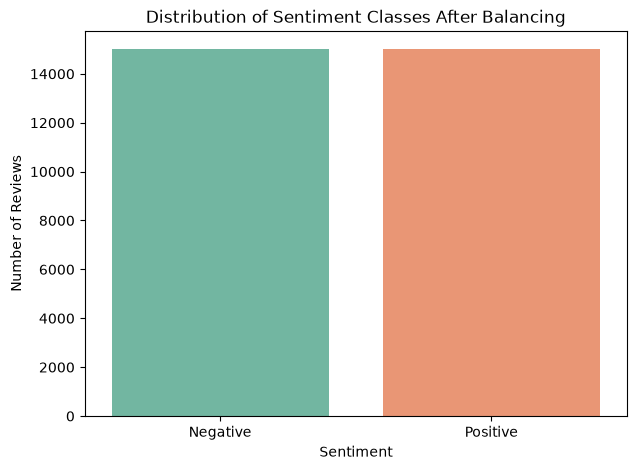

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_df,
    x='overall',
    hue='overall',
    palette='Set2',
    legend=False
)

plt.xticks([0, 1], ['Negative', 'Positive'])
plt.title('Distribution of Sentiment Classes After Balancing')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')

plt.show()

محاسبه و بررسی تعداد کلمات نظرات

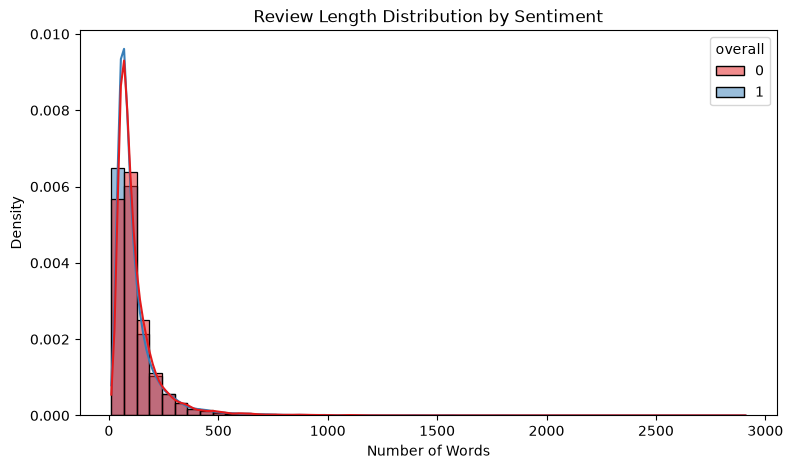

In [27]:
train_df['word_count'] = train_df['text'].apply(
    lambda x: len(x.split())
)

plt.figure(figsize=(9, 5))

sns.histplot(
    data=train_df,
    x='word_count',
    hue='overall',
    bins=50,
    kde=True,
    palette='Set1',
    stat='density',
    common_norm=False
)

plt.title('Review Length Distribution by Sentiment')
plt.xlabel('Number of Words')
plt.ylabel('Density')

plt.show()

محاسبه آمار توصیفی طول نظرات برای هر کلاس

In [28]:
length_analysis = train_df.groupby('overall')['word_count'].agg(
    ['mean', 'median', 'min', 'max', 'std']
)

print(length_analysis)

               mean  median  min   max         std
overall                                           
0        125.358400    88.0   14  2909  120.965762
1        121.688733    82.0   11  2377  126.632255


مقایسه طول نظرات در دو کلاس

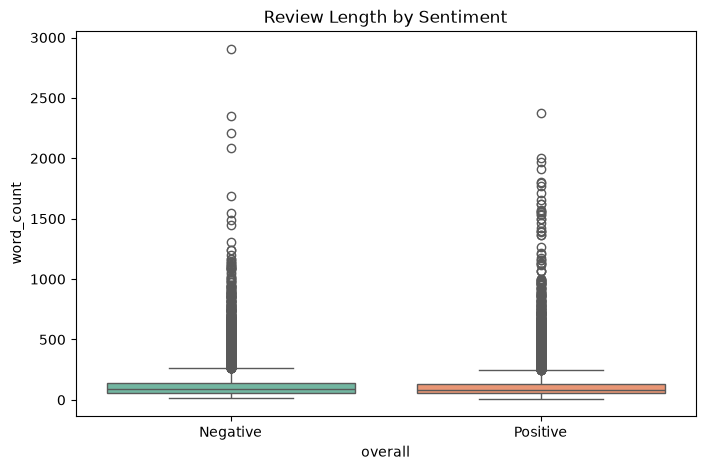

In [29]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_df,
    x='overall',
    y='word_count',
    hue='overall',
    palette='Set2',
    legend=False
)

plt.xticks([0, 1], ['Negative', 'Positive'])
plt.title('Review Length by Sentiment')

plt.show()

تعریف تابع استخراج کلمات پرتکرار

In [30]:
from collections import Counter

def get_top_words(data, label, n=20):

    words = []

    texts = data[
        data['overall'] == label
    ]['text']

    for text in texts:
        words.extend(text.split())

    return Counter(words).most_common(n)


negative_words = get_top_words(train_df, 0)
positive_words = get_top_words(train_df, 1)

print("Negative:", negative_words)
print("Positive:", positive_words)

Negative: [('the', 98699), ('i', 53529), ('to', 52087), ('and', 45284), ('a', 45140), ('it', 45121), ('is', 28889), ('of', 24972), ('this', 24535), ('for', 22738), ('not', 20297), ('in', 18561), ('that', 18386), ('but', 17956), ('my', 17693), ('on', 17324), ('with', 17038), ('you', 14157), ('have', 13650), ('was', 12902)]
Positive: [('the', 90686), ('i', 51607), ('and', 50708), ('to', 48410), ('a', 47864), ('it', 37679), ('is', 28830), ('for', 26602), ('this', 25339), ('of', 23907), ('my', 21705), ('with', 19555), ('in', 19389), ('that', 17286), ('on', 16481), ('you', 14215), ('have', 13849), ('but', 13471), ('not', 10917), ('as', 10762)]


نمایش مقایسه کلمات پرتکرار دو کلاس

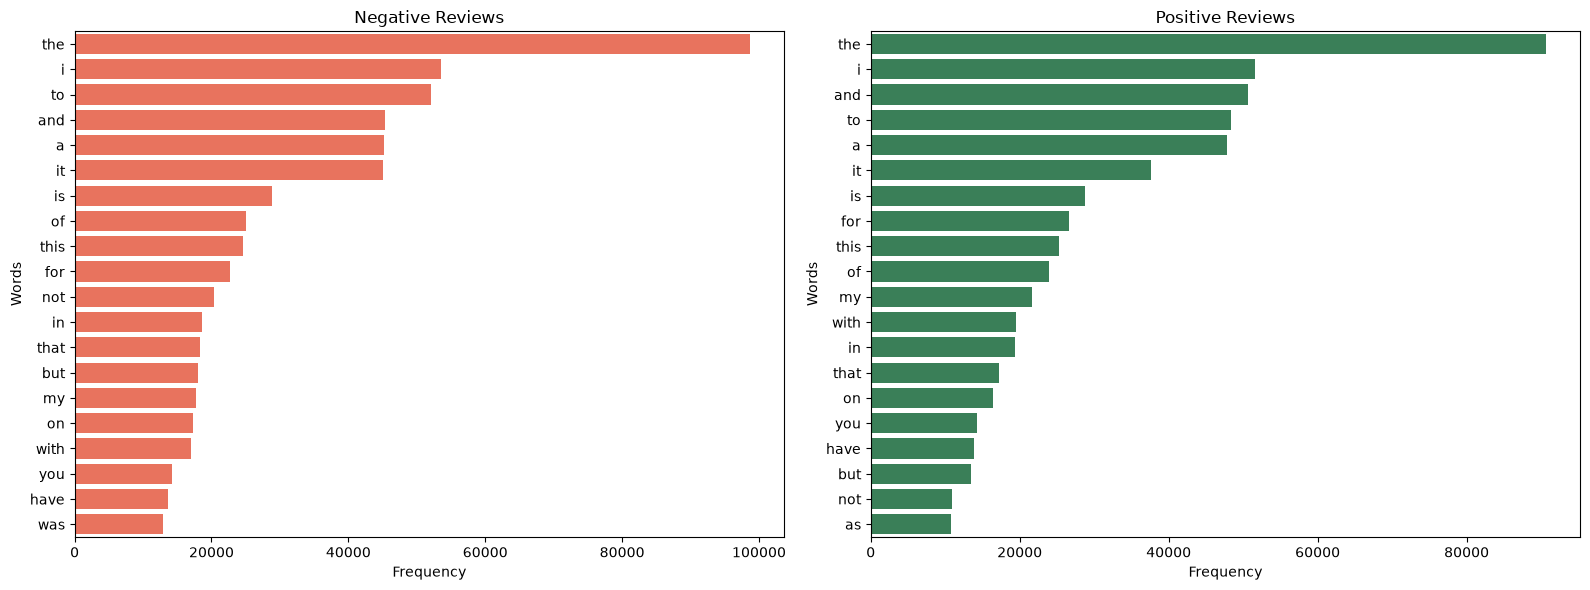

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, data, title, color in [
    (axes[0], negative_words, 'Negative Reviews', 'tomato'),
    (axes[1], positive_words, 'Positive Reviews', 'seagreen')
]:

    words, counts = zip(*data)

    sns.barplot(
        x=list(counts),
        y=list(words),
        ax=ax,
        color=color
    )

    ax.set_title(title)
    ax.set_xlabel('Frequency')
    ax.set_ylabel('Words')

plt.tight_layout()
plt.show()

استخراج بیگرام‌های پرتکرار

In [32]:
def get_top_bigrams(data, label, n=20):

    bigrams = []

    texts = data[
        data['overall'] == label
    ]['text']

    for text in texts:

        words = text.split()

        bigrams.extend([
            words[i] + "_" + words[i+1]
            for i in range(len(words)-1)
        ])

    return Counter(bigrams).most_common(n)


negative_bigrams = get_top_bigrams(train_df, 0)
positive_bigrams = get_top_bigrams(train_df, 1)

print("Negative Bigrams:", negative_bigrams)
print("Positive Bigrams:", positive_bigrams)

Negative Bigrams: [('of_the', 6786), ('on_the', 4951), ('i_have', 4680), ('in_the', 4658), ('it_is', 3848), ('to_the', 3700), ('and_the', 3471), ('for_the', 3382), ('with_the', 3333), ('if_you', 3225), ('is_a', 3017), ('to_be', 2887), ('for_a', 2854), ('this_is', 2792), ('it_was', 2670), ('i_was', 2616), ('have_to', 2497), ('i_had', 2413), ('and_it', 2284), ('and_i', 2212)]
Positive Bigrams: [('of_the', 6156), ('i_have', 5160), ('on_the', 4771), ('in_the', 4466), ('for_the', 4326), ('is_a', 3761), ('it_is', 3734), ('this_is', 3619), ('with_the', 3609), ('and_the', 3584), ('to_the', 3503), ('if_you', 3054), ('for_a', 2866), ('and_i', 2657), ('i_was', 2603), ('and_it', 2518), ('with_a', 2394), ('to_be', 2351), ('i_am', 2304), ('for_my', 2294)]


بررسی ماتریس انتقال حالت‌های مدل HMM

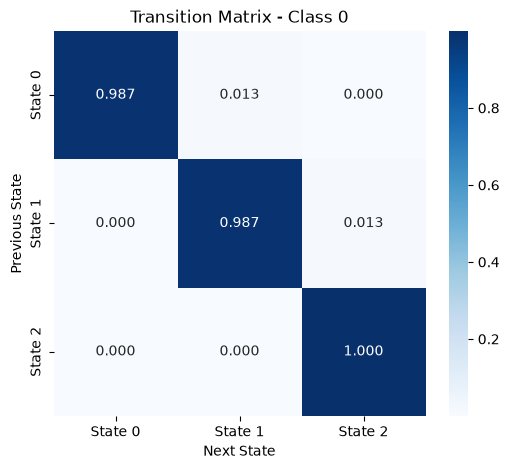

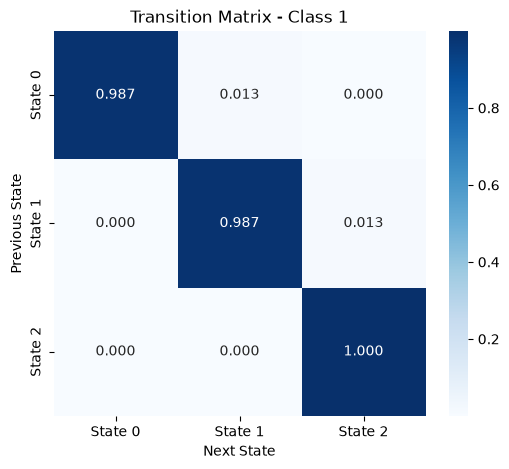

In [33]:
for label in CLASSES:

    model = final_models[label]

    transition_matrix = np.zeros((STATES, STATES))

    for i in range(STATES):
        for j in range(STATES):

            transition_matrix[i, j] = np.exp(
                model.transition_log[(i, j)]
            )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        transition_matrix,
        annot=True,
        fmt='.3f',
        cmap='Blues',
        xticklabels=['State 0', 'State 1', 'State 2'],
        yticklabels=['State 0', 'State 1', 'State 2']
    )

    plt.title(
        f'Transition Matrix - Class {label}'
    )

    plt.xlabel('Next State')
    plt.ylabel('Previous State')

    plt.show()